# imports + config

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import json, warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('inline')
import matplotlib.pyplot as plt
%matplotlib inline
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from pathlib import Path
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import shap
warnings.filterwarnings('ignore')

DEVICE       = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MODEL_ROOT   = Path('/content/drive/MyDrive/uav_thesis/model_outputs/v2')
ENRICHED_DIR = MODEL_ROOT / '07_enriched_parquets'
OUT_DIR      = MODEL_ROOT / '08_anomaly_regression'
PLOT_DIR     = OUT_DIR / 'plots'
OUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

FOLDS       = [f'fold_{i:02d}' for i in range(1, 6)]
TARGET      = 'target_energy_next_60s_wh'
OUTPUT_ROOT = Path('/content/drive/MyDrive/uav_thesis/processed_10hz/v2')

print(f'Device: {DEVICE}')
print(f'Enriched dir exists: {ENRICHED_DIR.exists()}')

Device: cuda
Enriched dir exists: True


# load enriched parquets

In [3]:
enriched = {}
for fold in FOLDS:
    fold_dir = OUTPUT_ROOT / fold
    with open(fold_dir / f'feature_cols_{fold}.json') as f:
        feature_cols = json.load(f)
    enriched[fold] = {
        'feature_cols': feature_cols,
        'train': pd.read_parquet(ENRICHED_DIR / f'train_enriched_{fold}.parquet'),
        'val':   pd.read_parquet(ENRICHED_DIR / f'val_enriched_{fold}.parquet'),
        'test':  pd.read_parquet(ENRICHED_DIR / f'test_enriched_{fold}.parquet'),
    }
    tr = enriched[fold]['train']
    te = enriched[fold]['test']
    print(f'{fold} | train={len(tr)} val={len(enriched[fold]["val"])} '
          f'test={len(te)} | features={len(feature_cols)} | '
          f'anomaly_score nulls={te["anomaly_score"].isna().sum()}')

fold_01 | train=665216 val=110878 test=190831 | features=16 | anomaly_score nulls=0
fold_02 | train=643038 val=105335 test=218552 | features=16 | anomaly_score nulls=0
fold_03 | train=677953 val=105412 test=183560 | features=16 | anomaly_score nulls=0
fold_04 | train=671181 val=114458 test=181286 | features=16 | anomaly_score nulls=0
fold_05 | train=648120 val=126109 test=192696 | features=16 | anomaly_score nulls=0


# helper functions

In [4]:
def get_Xy(df, feature_cols, use_anomaly):
    cols = feature_cols + (['anomaly_score'] if use_anomaly else [])
    return df[cols].values.astype(np.float32), df[TARGET].values.astype(np.float32)

def compute_metrics(y_true, y_pred, mean_power_w=None):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    mask = y_true > 0.01
    mape = np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100
    rft  = (mae / mean_power_w * 3600) if mean_power_w else None
    return {'MAE': mae, 'RMSE': rmse, 'R2': r2, 'MAPE': mape, 'RFT_err_s': rft}

def wilcoxon_test(mae_baseline, mae_with):
    # one-sided: does +anomaly reduce MAE?
    diffs = np.array(mae_baseline) - np.array(mae_with)
    if np.all(diffs == 0):
        return np.nan, np.nan
    stat, p = stats.wilcoxon(diffs, alternative='greater')
    return stat, p

# tree baseline models (LR, RF, XGBoost)

In [5]:
tree_results = []

for fold in FOLDS:
    fc   = enriched[fold]['feature_cols']
    df_tr = pd.concat([enriched[fold]['train'], enriched[fold]['val']], ignore_index=True)
    df_va = enriched[fold]['val']
    df_te = enriched[fold]['test']
    mean_pw = df_te['power_w'].mean() if 'power_w' in df_te.columns else None

    models_cfg = {
        'LinearRegression': LinearRegression(),
        'RandomForest': RandomForestRegressor(
            n_estimators=300, max_depth=15, min_samples_leaf=10,
            max_features=0.5, n_jobs=-1, random_state=42),
        'XGBoost': XGBRegressor(
            n_estimators=1000, max_depth=5, learning_rate=0.01,
            min_child_weight=10, subsample=0.8, colsample_bytree=0.8,
            early_stopping_rounds=50, random_state=42, verbosity=0, n_jobs=-1),
    }

    for model_name, mdl in models_cfg.items():
        for use_anomaly in [False, True]:
            X_tr, y_tr = get_Xy(df_tr, fc, use_anomaly)
            X_te, y_te = get_Xy(df_te, fc, use_anomaly)

            if model_name == 'XGBoost':
                X_va, y_va = get_Xy(df_va, fc, use_anomaly)
                mdl.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
            else:
                mdl.fit(X_tr, y_tr)

            preds = mdl.predict(X_te)
            m = compute_metrics(y_te, preds, mean_pw)

            # subgroup MAE
            normal_mask   = df_te['dataset_label'] == 'normal'
            abnormal_mask = df_te['dataset_label'] == 'abnormal'
            m['MAE_normal']   = mean_absolute_error(y_te[normal_mask],   preds[normal_mask])   if normal_mask.any()   else np.nan
            m['MAE_abnormal'] = mean_absolute_error(y_te[abnormal_mask], preds[abnormal_mask]) if abnormal_mask.any() else np.nan

            m.update({'fold': fold, 'model': model_name,
                      'condition': 'with_anomaly' if use_anomaly else 'baseline'})
            tree_results.append(m)
            print(f'{fold} | {model_name:18s} | {"w/ anom" if use_anomaly else "baseline":10s} | '
                  f'MAE={m["MAE"]:.4f} RMSE={m["RMSE"]:.4f} R2={m["R2"]:.3f} '
                  f'MAPE={m["MAPE"]:.1f}% RFT={m["RFT_err_s"]:.1f}s')

df_tree = pd.DataFrame(tree_results)
df_tree.to_parquet(OUT_DIR / 'tree_model_results.parquet', index=False)

fold_01 | LinearRegression   | baseline   | MAE=0.4629 RMSE=0.7937 R2=0.851 MAPE=401.6% RFT=10050.3s
fold_01 | LinearRegression   | w/ anom    | MAE=0.4629 RMSE=0.7937 R2=0.851 MAPE=401.6% RFT=10050.3s
fold_01 | RandomForest       | baseline   | MAE=0.4138 RMSE=0.8825 R2=0.816 MAPE=137.7% RFT=8984.2s
fold_01 | RandomForest       | w/ anom    | MAE=0.5586 RMSE=1.0562 R2=0.736 MAPE=355.9% RFT=12129.9s
fold_01 | XGBoost            | baseline   | MAE=0.4074 RMSE=0.8833 R2=0.816 MAPE=152.0% RFT=8845.8s
fold_01 | XGBoost            | w/ anom    | MAE=0.4638 RMSE=0.9433 R2=0.790 MAPE=208.7% RFT=10070.4s
fold_02 | LinearRegression   | baseline   | MAE=0.7343 RMSE=1.8396 R2=0.896 MAPE=74.0% RFT=3021.1s
fold_02 | LinearRegression   | w/ anom    | MAE=0.7343 RMSE=1.8396 R2=0.896 MAPE=74.0% RFT=3021.1s
fold_02 | RandomForest       | baseline   | MAE=1.1876 RMSE=3.3739 R2=0.649 MAPE=149.4% RFT=4885.8s
fold_02 | RandomForest       | w/ anom    | MAE=1.2840 RMSE=3.4439 R2=0.634 MAPE=192.2% RFT=5282.5

# LSTM and BiLSTM architecture

In [6]:
class LSTMRegressor(nn.Module):
    def __init__(self, n_features, hidden=128, layers=2, dropout=0.2, bidirectional=False):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, num_layers=layers,
                            dropout=dropout, batch_first=True,
                            bidirectional=bidirectional)
        fc_in = hidden * 2 if bidirectional else hidden
        self.fc = nn.Sequential(
            nn.Linear(fc_in, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :]).squeeze(-1)


def make_sequences(df, feature_cols, target, window=50, stride=10):
    X_list, y_list = [], []
    for _, grp in df.groupby('log_id', sort=False):
        vals = grp[feature_cols].values.astype(np.float32)
        tgt  = grp[target].values.astype(np.float32)
        for i in range(0, len(vals) - window + 1, stride):
            X_list.append(vals[i:i+window])
            y_list.append(tgt[i + window - 1])
    return np.array(X_list), np.array(y_list)


def train_lstm(model, X_tr, y_tr, X_va, y_va,
               lr=1e-3, epochs=100, patience=10, batch=256):
    opt      = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn  = nn.MSELoss()
    tr_ds    = TensorDataset(torch.tensor(X_tr), torch.tensor(y_tr))
    tr_dl    = DataLoader(tr_ds, batch_size=batch, shuffle=True)
    X_va_t   = torch.tensor(X_va).to(DEVICE)
    y_va_t   = torch.tensor(y_va).to(DEVICE)

    best_val, patience_ctr, best_state = np.inf, 0, None
    for epoch in range(epochs):
        model.train()
        for xb, yb in tr_dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss_fn(model(xb), yb).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(X_va_t), y_va_t).item()
        if val_loss < best_val:
            best_val    = val_loss
            best_state  = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            patience_ctr = 0
        else:
            patience_ctr += 1
            if patience_ctr >= patience:
                break
    model.load_state_dict(best_state)
    return model


def predict_lstm(model, X, batch=512):
    model.eval()
    preds = []
    with torch.no_grad():
        for i in range(0, len(X), batch):
            xb = torch.tensor(X[i:i+batch]).to(DEVICE)
            preds.append(model(xb).cpu().numpy())
    return np.concatenate(preds)

# run LSTM and BiLSTM

In [10]:
WINDOW, STRIDE = 50, 10
seq_results = []

for fold in FOLDS:
    fc      = enriched[fold]['feature_cols']
    df_tr   = enriched[fold]['train']
    df_va   = enriched[fold]['val']
    df_te   = enriched[fold]['test']
    mean_pw = df_te['power_w'].mean() if 'power_w' in df_te.columns else None

    for use_anomaly in [False, True]:
        cols   = fc + (['anomaly_score'] if use_anomaly else [])
        n_feat = len(cols)

        X_tr, y_tr = make_sequences(df_tr, cols, TARGET, WINDOW, STRIDE)
        X_va, y_va = make_sequences(df_va, cols, TARGET, WINDOW, STRIDE)
        X_te, y_te = make_sequences(df_te, cols, TARGET, WINDOW, STRIDE)

        # rebuild label masks aligned to sequence windows
        te_idx = []
        for _, grp in df_te.groupby('log_id', sort=False):
            n = len(grp)
            for i in range(0, n - WINDOW + 1, STRIDE):
                te_idx.append(grp.index[i + WINDOW - 1])
        te_labels = df_te.loc[te_idx, 'dataset_label'].values
        norm_seq  = te_labels == 'normal'
        abn_seq   = te_labels == 'abnormal'

        for arch, bidir in [('LSTM', False), ('BiLSTM', True)]:

            # ── checkpoint skip ──
            ckpt = OUT_DIR / f'{arch.lower()}_{fold}_{"anom" if use_anomaly else "base"}.pt'
            if ckpt.exists():
                print(f'  Skipping {arch} {fold} {"anom" if use_anomaly else "base"} — checkpoint exists')
                continue

            print(f'{fold} | {arch} | {"w/ anom" if use_anomaly else "baseline"} ...', end=' ')
            model = LSTMRegressor(n_feat, hidden=128, layers=2,
                                  dropout=0.2, bidirectional=bidir).to(DEVICE)
            model = train_lstm(model, X_tr, y_tr, X_va, y_va,
                               lr=1e-3, epochs=100, patience=10, batch=256)
            preds = predict_lstm(model, X_te)
            m = compute_metrics(y_te, preds, mean_pw)
            m['MAE_normal']   = mean_absolute_error(y_te[norm_seq], preds[norm_seq]) if norm_seq.any() else np.nan
            m['MAE_abnormal'] = mean_absolute_error(y_te[abn_seq],  preds[abn_seq])  if abn_seq.any()  else np.nan
            m.update({'fold': fold, 'model': arch,
                      'condition': 'with_anomaly' if use_anomaly else 'baseline'})
            seq_results.append(m)

            # save weights + partial results
            torch.save(model.state_dict(), ckpt)
            pd.DataFrame(seq_results).to_parquet(OUT_DIR / 'seq_results_partial.parquet', index=False)
            print(f'MAE={m["MAE"]:.4f} RMSE={m["RMSE"]:.4f} R2={m["R2"]:.3f}')

df_seq = pd.DataFrame(seq_results)
df_seq.to_parquet(OUT_DIR / 'seq_model_results.parquet', index=False)

  Skipping LSTM fold_01 base — checkpoint exists
  Skipping BiLSTM fold_01 base — checkpoint exists
  Skipping LSTM fold_01 anom — checkpoint exists
  Skipping BiLSTM fold_01 anom — checkpoint exists
  Skipping LSTM fold_02 base — checkpoint exists
  Skipping BiLSTM fold_02 base — checkpoint exists
  Skipping LSTM fold_02 anom — checkpoint exists
  Skipping BiLSTM fold_02 anom — checkpoint exists
  Skipping LSTM fold_03 base — checkpoint exists
  Skipping BiLSTM fold_03 base — checkpoint exists
  Skipping LSTM fold_03 anom — checkpoint exists
  Skipping BiLSTM fold_03 anom — checkpoint exists
  Skipping LSTM fold_04 base — checkpoint exists
  Skipping BiLSTM fold_04 base — checkpoint exists
  Skipping LSTM fold_04 anom — checkpoint exists
  Skipping BiLSTM fold_04 anom — checkpoint exists
  Skipping LSTM fold_05 base — checkpoint exists
fold_05 | BiLSTM | baseline ... MAE=0.5128 RMSE=0.8691 R2=0.844
fold_05 | LSTM | w/ anom ... MAE=0.6263 RMSE=0.9885 R2=0.799
fold_05 | BiLSTM | w/ anom

# combine results + Wilcoxon test

In [11]:
df_all = pd.concat([df_tree, df_seq], ignore_index=True)

print('=== Mean ± std across 5 folds ===\n')
summary_rows = []
for model in ['LinearRegression', 'RandomForest', 'XGBoost', 'LSTM', 'BiLSTM']:
    for cond in ['baseline', 'with_anomaly']:
        sub = df_all[(df_all['model'] == model) & (df_all['condition'] == cond)]
        if sub.empty:
            continue
        row = {'model': model, 'condition': cond}
        for col in ['MAE', 'RMSE', 'R2', 'MAPE', 'RFT_err_s',
                    'MAE_normal', 'MAE_abnormal']:
            row[f'{col}_mean'] = sub[col].mean()
            row[f'{col}_std']  = sub[col].std()
        summary_rows.append(row)

df_summary = pd.DataFrame(summary_rows)

# Wilcoxon per model
print('=== Wilcoxon signed-rank (baseline MAE vs with_anomaly MAE) ===\n')
wilcoxon_rows = []
for model in ['LinearRegression', 'RandomForest', 'XGBoost', 'LSTM', 'BiLSTM']:
    base = df_all[(df_all['model'] == model) & (df_all['condition'] == 'baseline')].sort_values('fold')['MAE'].values
    with_ = df_all[(df_all['model'] == model) & (df_all['condition'] == 'with_anomaly')].sort_values('fold')['MAE'].values
    if len(base) < 2:
        continue
    stat, p = wilcoxon_test(base, with_)
    delta = (base.mean() - with_.mean())
    wilcoxon_rows.append({'model': model, 'MAE_base': base.mean(),
                          'MAE_with': with_.mean(), 'delta_MAE': delta,
                          'W_stat': stat, 'p_value': p,
                          'significant': p < 0.05 if not np.isnan(p) else False})
    print(f'{model:18s} | base={base.mean():.4f} with={with_.mean():.4f} '
          f'delta={delta:.4f} | W={stat} p={p:.4f} {"✓" if p < 0.05 else "✗"}')

df_wilcoxon = pd.DataFrame(wilcoxon_rows)

df_summary.to_csv(OUT_DIR / 'summary_all_models.csv', index=False)
df_wilcoxon.to_csv(OUT_DIR / 'wilcoxon_results.csv', index=False)
df_all.to_parquet(OUT_DIR / 'all_results.parquet', index=False)

=== Mean ± std across 5 folds ===

=== Wilcoxon signed-rank (baseline MAE vs with_anomaly MAE) ===

LinearRegression   | base=0.5634 with=0.5634 delta=-0.0000 | W=2.5 p=0.9375 ✗
RandomForest       | base=0.8152 with=0.8737 delta=-0.0585 | W=2.0 p=0.9375 ✗
XGBoost            | base=0.7224 with=0.7734 delta=-0.0510 | W=3.0 p=0.9062 ✗


# plots

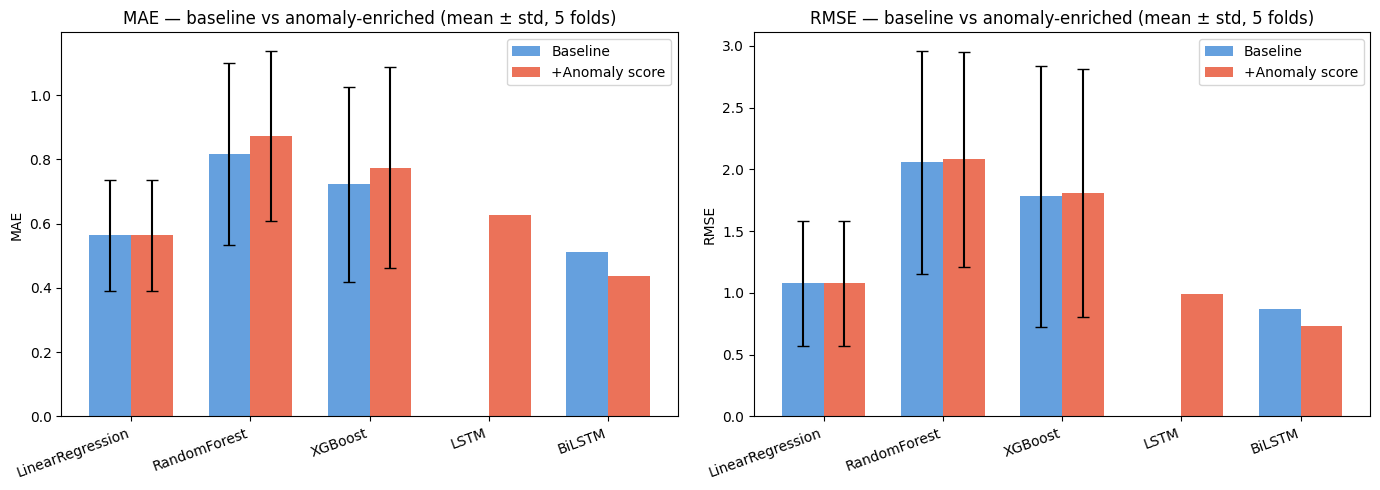

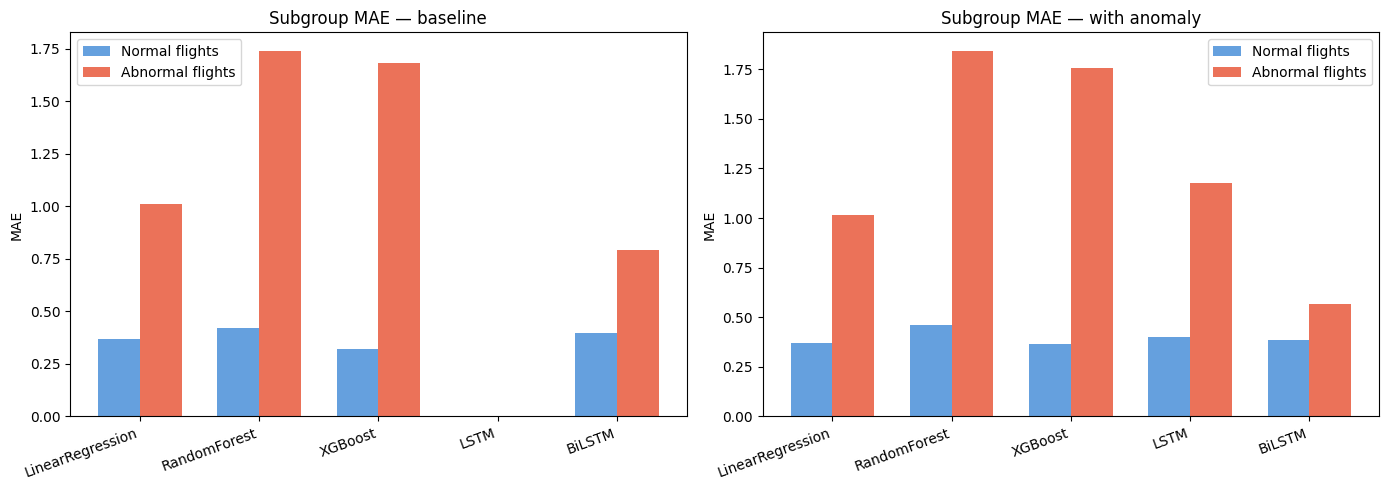

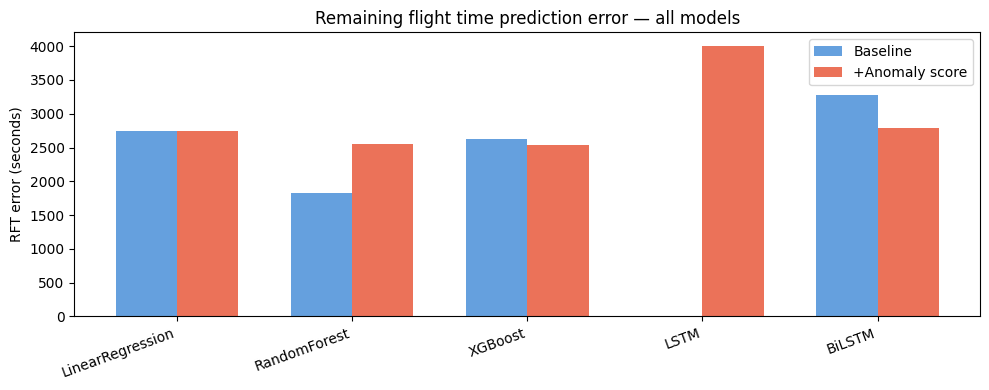

In [12]:
MODELS = ['LinearRegression', 'RandomForest', 'XGBoost', 'LSTM', 'BiLSTM']
COLORS = {'baseline': '#4A90D9', 'with_anomaly': '#E8593C'}

# ── Plot 1: MAE with vs without, per model ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric in zip(axes, ['MAE', 'RMSE']):
    x = np.arange(len(MODELS))
    w = 0.35
    for i, cond in enumerate(['baseline', 'with_anomaly']):
        means = [df_summary.loc[(df_summary['model']==m)&(df_summary['condition']==cond),
                                f'{metric}_mean'].values[0]
                 if len(df_summary.loc[(df_summary['model']==m)&(df_summary['condition']==cond)]) > 0
                 else np.nan for m in MODELS]
        stds  = [df_summary.loc[(df_summary['model']==m)&(df_summary['condition']==cond),
                                f'{metric}_std'].values[0]
                 if len(df_summary.loc[(df_summary['model']==m)&(df_summary['condition']==cond)]) > 0
                 else np.nan for m in MODELS]
        ax.bar(x + (i-0.5)*w, means, w, yerr=stds, capsize=4,
               color=COLORS[cond], alpha=0.85,
               label='Baseline' if cond == 'baseline' else '+Anomaly score')
    ax.set_xticks(x)
    ax.set_xticklabels(MODELS, rotation=20, ha='right')
    ax.set_ylabel(metric)
    ax.set_title(f'{metric} — baseline vs anomaly-enriched (mean ± std, 5 folds)')
    ax.legend()
plt.tight_layout()
plt.savefig(PLOT_DIR / 'mae_rmse_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Plot 2: Normal vs Abnormal MAE subgroup ───────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, cond in zip(axes, ['baseline', 'with_anomaly']):
    sub = df_summary[df_summary['condition'] == cond]
    x   = np.arange(len(MODELS))
    w   = 0.35
    norm_means = [sub.loc[sub['model']==m, 'MAE_normal_mean'].values[0]
                  if len(sub.loc[sub['model']==m]) > 0 else np.nan for m in MODELS]
    abn_means  = [sub.loc[sub['model']==m, 'MAE_abnormal_mean'].values[0]
                  if len(sub.loc[sub['model']==m]) > 0 else np.nan for m in MODELS]
    ax.bar(x - w/2, norm_means, w, color='#4A90D9', alpha=0.85, label='Normal flights')
    ax.bar(x + w/2, abn_means,  w, color='#E8593C', alpha=0.85, label='Abnormal flights')
    ax.set_xticks(x)
    ax.set_xticklabels(MODELS, rotation=20, ha='right')
    ax.set_ylabel('MAE')
    ax.set_title(f'Subgroup MAE — {cond.replace("_"," ")}')
    ax.legend()
plt.tight_layout()
plt.savefig(PLOT_DIR / 'subgroup_mae_normal_vs_abnormal.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Plot 3: RFT error per model ───────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(MODELS))
w = 0.35
for i, cond in enumerate(['baseline', 'with_anomaly']):
    rft = [df_summary.loc[(df_summary['model']==m)&(df_summary['condition']==cond),
                           'RFT_err_s_mean'].values[0]
           if len(df_summary.loc[(df_summary['model']==m)&(df_summary['condition']==cond)]) > 0
           else np.nan for m in MODELS]
    ax.bar(x + (i-0.5)*w, rft, w,
           color=COLORS[cond], alpha=0.85,
           label='Baseline' if cond == 'baseline' else '+Anomaly score')
ax.set_xticks(x)
ax.set_xticklabels(MODELS, rotation=20, ha='right')
ax.set_ylabel('RFT error (seconds)')
ax.set_title('Remaining flight time prediction error — all models')
ax.legend()
plt.tight_layout()
plt.savefig(PLOT_DIR / 'rft_error_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# SHAP for best tree model

In [16]:
print(X_tr.shape)
print(X_te.shape)

(776094, 18)
(190831, 18)


X_tr shape: (776094, 17)  cols: 17
shap_vals shape: (2000, 17)
cols length    : 17
anomaly_score SHAP rank: 9 of 17


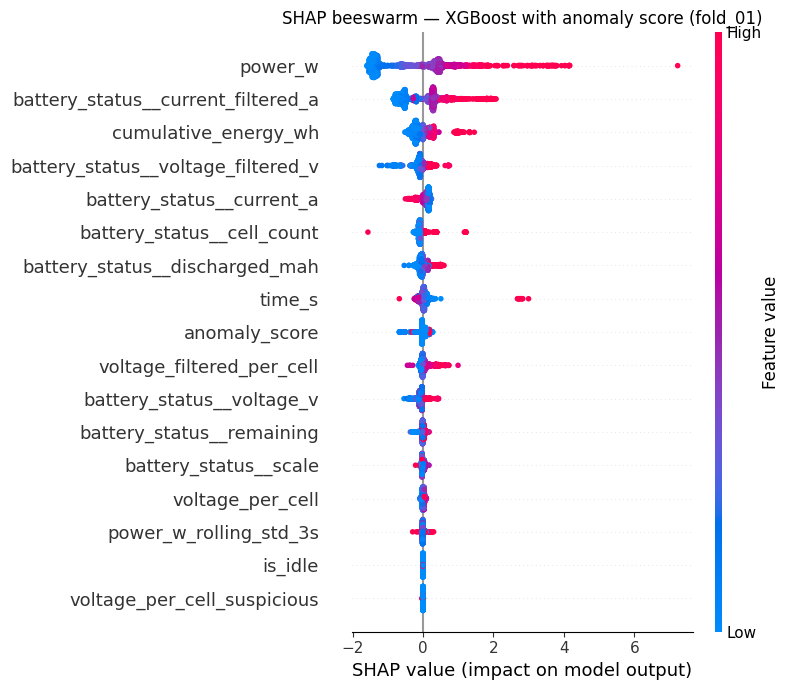

anomaly_score mean |SHAP| — normal  : 0.07605
anomaly_score mean |SHAP| — abnormal: 0.11306


In [17]:
BEST_TREE = 'XGBoost'

fold  = 'fold_01'
fc    = enriched[fold]['feature_cols']
cols  = [c for c in fc if c != 'anomaly_flag'] + ['anomaly_score']  # exclude anomaly_flag
df_tr = pd.concat([enriched[fold]['train'], enriched[fold]['val']], ignore_index=True)
df_va = enriched[fold]['val']
df_te = enriched[fold]['test']

X_tr = df_tr[cols].values.astype(np.float32); y_tr = df_tr[TARGET].values.astype(np.float32)
X_va = df_va[cols].values.astype(np.float32); y_va = df_va[TARGET].values.astype(np.float32)
X_te = df_te[cols].values.astype(np.float32); y_te = df_te[TARGET].values.astype(np.float32)

print(f'X_tr shape: {X_tr.shape}  cols: {len(cols)}')

if BEST_TREE == 'XGBoost':
    mdl = XGBRegressor(n_estimators=1000, max_depth=5, learning_rate=0.01,
                       min_child_weight=10, subsample=0.8, colsample_bytree=0.8,
                       early_stopping_rounds=50, random_state=42, verbosity=0, n_jobs=-1)
    mdl.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    explainer = shap.TreeExplainer(mdl)
else:
    mdl = RandomForestRegressor(n_estimators=300, max_depth=15, min_samples_leaf=10,
                                max_features=0.5, n_jobs=-1, random_state=42)
    mdl.fit(X_tr, y_tr)
    explainer = shap.TreeExplainer(mdl)

# sample 2000 rows
idx       = np.random.choice(len(X_te), min(2000, len(X_te)), replace=False)
shap_vals = explainer.shap_values(X_te[idx])

print(f'shap_vals shape: {shap_vals.shape}')
print(f'cols length    : {len(cols)}')
assert shap_vals.shape[1] == len(cols), f'Mismatch: {shap_vals.shape[1]} vs {len(cols)}'

# beeswarm
shap.summary_plot(shap_vals, X_te[idx], feature_names=cols,
                  show=False, plot_size=(8, 7))
anom_idx  = cols.index('anomaly_score')
rank      = np.argsort(np.abs(shap_vals).mean(0))[::-1].tolist().index(anom_idx) + 1
print(f'anomaly_score SHAP rank: {rank} of {len(cols)}')
plt.title(f'SHAP beeswarm — {BEST_TREE} with anomaly score (fold_01)')
plt.tight_layout()
plt.savefig(PLOT_DIR / 'shap_beeswarm.png', dpi=150, bbox_inches='tight')
plt.show()

# normal vs abnormal SHAP for anomaly_score
normal_idx   = np.where(df_te['dataset_label'].values[idx] == 'normal')[0]
abnormal_idx = np.where(df_te['dataset_label'].values[idx] == 'abnormal')[0]
print(f'anomaly_score mean |SHAP| — normal  : {np.abs(shap_vals[normal_idx, anom_idx]).mean():.5f}')
print(f'anomaly_score mean |SHAP| — abnormal: {np.abs(shap_vals[abnormal_idx, anom_idx]).mean():.5f}')

# per-flight timeline plot

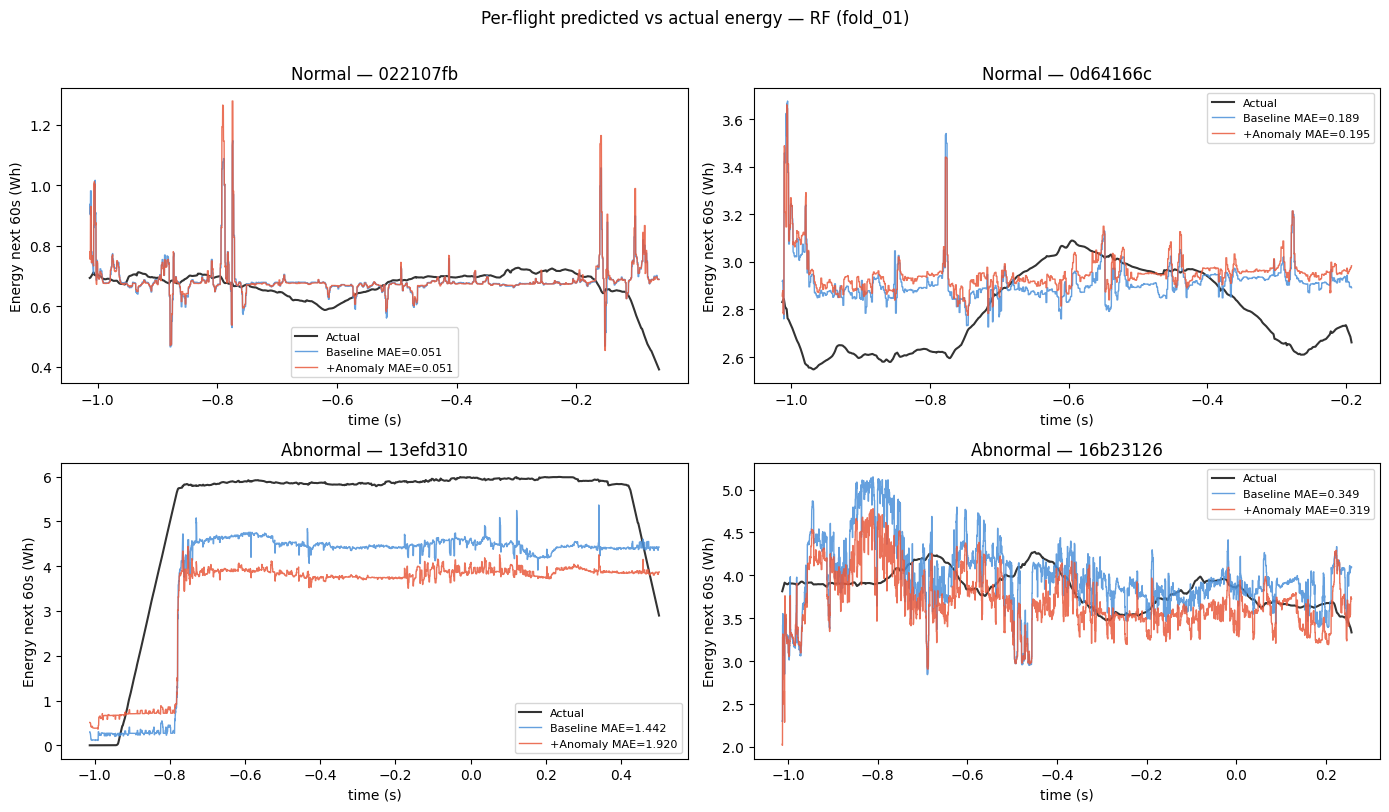

In [18]:
# 2 normal + 2 abnormal flights, best model, with vs without anomaly
fold  = 'fold_01'
fc    = enriched[fold]['feature_cols']
df_te = enriched[fold]['test']

normal_ids   = df_te[df_te['dataset_label'] == 'normal']['log_id'].unique()[:2]
abnormal_ids = df_te[df_te['dataset_label'] == 'abnormal']['log_id'].unique()[:2]
flight_ids   = list(normal_ids) + list(abnormal_ids)
labels       = ['Normal', 'Normal', 'Abnormal', 'Abnormal']

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

# refit RF quickly on fold_01 for both conditions
models_plot = {}
df_tr = pd.concat([enriched[fold]['train'], enriched[fold]['val']], ignore_index=True)
df_va = enriched[fold]['val']
for use_anomaly in [False, True]:
    cols = fc + (['anomaly_score'] if use_anomaly else [])
    X_tr, y_tr = get_Xy(df_tr, fc, use_anomaly)
    mdl = RandomForestRegressor(n_estimators=100, max_depth=15, min_samples_leaf=10,
                                max_features=0.5, n_jobs=-1, random_state=42)
    mdl.fit(X_tr, y_tr)
    models_plot[use_anomaly] = (mdl, cols)

for ax, fid, lbl in zip(axes, flight_ids, labels):
    grp  = df_te[df_te['log_id'] == fid].reset_index(drop=True)
    t    = grp['time_s'].values
    ytrue = grp[TARGET].values
    ax.plot(t, ytrue, 'k-', lw=1.5, label='Actual', alpha=0.8)
    for use_anomaly, color, name in [(False, '#4A90D9', 'Baseline'),
                                      (True,  '#E8593C', '+Anomaly')]:
        mdl, cols = models_plot[use_anomaly]
        X = grp[cols].values.astype(np.float32)
        pred = mdl.predict(X)
        mae  = mean_absolute_error(ytrue, pred)
        ax.plot(t, pred, color=color, lw=1, alpha=0.85, label=f'{name} MAE={mae:.3f}')
    ax.set_title(f'{lbl} — {fid[:8]}')
    ax.set_xlabel('time (s)')
    ax.set_ylabel('Energy next 60s (Wh)')
    ax.legend(fontsize=8)

plt.suptitle('Per-flight predicted vs actual energy — RF (fold_01)', y=1.01)
plt.tight_layout()
plt.savefig(PLOT_DIR / 'per_flight_timeline.png', dpi=150, bbox_inches='tight')
plt.show()

# final summary

In [19]:
print('=' * 70)
print('NOTEBOOK 08 COMPLETE')
print('=' * 70)

print('\n--- Best model by MAE (with anomaly score) ---')
best = df_summary[df_summary['condition'] == 'with_anomaly'].nsmallest(1, 'MAE_mean')
print(best[['model', 'MAE_mean', 'RMSE_mean', 'R2_mean', 'MAPE_mean', 'RFT_err_s_mean']].to_string(index=False))

print('\n--- Wilcoxon summary ---')
print(df_wilcoxon[['model', 'delta_MAE', 'p_value', 'significant']].to_string(index=False))

print('\n--- Files saved ---')
for f in sorted(OUT_DIR.rglob('*')):
    if f.is_file():
        print(f'  {f.relative_to(OUT_DIR)}')

NOTEBOOK 08 COMPLETE

--- Best model by MAE (with anomaly score) ---
 model  MAE_mean  RMSE_mean  R2_mean  MAPE_mean  RFT_err_s_mean
BiLSTM  0.437289   0.733653 0.889118  83.864555     2795.953427

--- Wilcoxon summary ---
           model  delta_MAE  p_value  significant
LinearRegression  -0.000002  0.93750        False
    RandomForest  -0.058540  0.93750        False
         XGBoost  -0.051020  0.90625        False

--- Files saved ---
  all_results.parquet
  bilstm_fold_01_anom.pt
  bilstm_fold_01_base.pt
  bilstm_fold_02_anom.pt
  bilstm_fold_02_base.pt
  bilstm_fold_03_anom.pt
  bilstm_fold_03_base.pt
  bilstm_fold_04_anom.pt
  bilstm_fold_04_base.pt
  bilstm_fold_05_anom.pt
  bilstm_fold_05_base.pt
  lstm_fold_01_anom.pt
  lstm_fold_01_base.pt
  lstm_fold_02_anom.pt
  lstm_fold_02_base.pt
  lstm_fold_03_anom.pt
  lstm_fold_03_base.pt
  lstm_fold_04_anom.pt
  lstm_fold_04_base.pt
  lstm_fold_05_anom.pt
  lstm_fold_05_base.pt
  plots/mae_rmse_comparison.png
  plots/per_flight_tim